# Applied Finance with Python
## Case Study 3: The Quarterly Client Report (reference solution)

Ms. Keller receives a report with three charts every quarter. Your predecessor built them by hand in Excel.
This notebook rebuilds all three charts in Python, so they can be reused for any client
by changing only the portfolio definition.

| Chart | Question from Ms. Keller | Finance concept |
|---|---|---|
| 1 · Performance since purchase | Which stock has performed best since I bought it? | Rebasing (index = 100) |
| 2 · Where does my return come from? | For which stock do dividends make up the largest share of my return? | Price return vs. total return |
| 3 · How deep did it fall? | Where would I have lost the most money along the way? | Drawdown |

> **Lecturer note:** this is the reference solution. The student template keeps only sections 1 and 2 (setup and data load).

# Lernfall 3: Der Quartalsreport
 
Frau Keller war mit eurer Auswertung sehr zufrieden. Am nächsten Morgen steht eure Chefin schon wieder an eurem Schreibtisch:
 
> *„Frau Keller bekommt von uns jedes Quartal eine Grafik, die zeigt, wie sich ihre Aktien seit dem Kauf entwickelt haben. Euer Vorgänger hat sie immer von Hand in Excel gebaut. Baut sie in Python nach, und zwar so, dass sie für jede Kundin funktioniert.“*
 
Zur Erinnerung, das Portfolio von Frau Keller:
 
| Aktie                    | Kaufdatum          |
|--------------------------|--------------------|
| Allianz SE               | 30. September 2021 |
| SAP SE                   | 15. März 2022      |
| Infineon Technologies AG | 1. Juni 2022       |
| Deutsche Telekom AG      | 3. Januar 2023     |
| Münchener Rück AG        | 29. September 2023 |
 
## Eure Aufgaben
 
1. Baut die Grafik in Python nach. Sie soll inhaltlich identisch sein: gleiche Daten, gleicher Diagrammtyp, gleicher Titel, gleiche Achsenbeschriftung und Legende. Farben und Größen müssen nur sinngemäß übereinstimmen.
2. Beantwortet die beiden Fragen von Frau Keller:
   - „Welche meiner Aktien hat sich seit dem Kauf am besten entwickelt?“
   - „Warum kann ich das nicht einfach an den Aktienkursen in Euro ablesen?“
 

# Wissenslücken

1. Wie kann ich in Python Grafiken bzw. Diagramme erstellen und darstellen?
2. Warum beginnt jede Aktie im Diagramm bei einem Wert von 100?
3. Warum starten die Kursverläufe der Aktien nicht alle am selben Tag?

## 1 · Setup

In [17]:
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt

### Client portfolio
Change only this cell to run the report for another client.

In [18]:
portfolio = [
    {"name": "Allianz SE",               "ticker": "ALV.DE",  "buy_date": "2021-09-30"},
    {"name": "SAP SE",                   "ticker": "SAP.DE",  "buy_date": "2022-03-15"},
    {"name": "Infineon Technologies AG", "ticker": "IFX.DE",  "buy_date": "2022-06-01"},
    {"name": "Deutsche Telekom AG",      "ticker": "DTE.DE",  "buy_date": "2023-01-03"},
    {"name": "Münchener Rück AG",        "ticker": "MUV2.DE", "buy_date": "2023-09-29"},
]

end_date = "2026-09-23"   # date of the evaluation (inclusive)

## 2 · Data load
Downloads `Close` and `Adj Close` for all stocks from Yahoo Finance (`auto_adjust=False`)
and stores them as a snapshot CSV. With `USE_SNAPSHOT = True` the notebook reads the frozen file instead,
so every student works with exactly the same numbers.

*Source: Yahoo Finance via `yfinance`, Xetra listings (`.DE`), prices in EUR.*

In [19]:
def download_prices(portfolio, end_date):
    # Download Close and Adj Close for all tickers. Returns a DataFrame with MultiIndex columns (field, ticker).
    tickers = [s["ticker"] for s in portfolio]
    start = min(s["buy_date"] for s in portfolio)
    end_exclusive = (pd.Timestamp(end_date) + pd.Timedelta(days=1)).strftime("%Y-%m-%d")  # yfinance: end is exclusive
    data = yf.download(tickers, start=start, end=end_exclusive, auto_adjust=False, progress=False)
    return data[["Close", "Adj Close"]]


def load_prices(portfolio, end_date):
    data = download_prices(portfolio, end_date)
    return data


prices = load_prices(portfolio, end_date)
close = prices["Close"]
adj_close = prices["Adj Close"]

print(f"{len(prices)} trading days from {prices.index[0].date()} to {prices.index[-1].date()}")
adj_close.tail()

1270 trading days from 2021-09-30 to 2026-09-23


Ticker,ALV.DE,DTE.DE,IFX.DE,MUV2.DE,SAP.DE
Date,,,,,
2026-09-17,451.100006,28.299999,54.400002,510.600006,188.000000
2026-09-18,443.299988,27.110001,55.860001,505.799988,183.119995
2026-09-21,445.100006,27.290001,58.290001,508.799988,182.860001
2026-09-22,430.200012,27.110001,60.130001,501.799988,182.320007
2026-09-23,413.100006,26.830000,58.570000,502.600006,186.460007


## 3 · Chart 1: Performance since purchase

Each stock is rebased to **100 on its own purchase date**: `index = price / price on purchase date × 100`.
Without rebasing, a stock priced at 400 € and one priced at 25 € cannot be compared on the same axis.
We use `Adj Close`, so dividends are included.

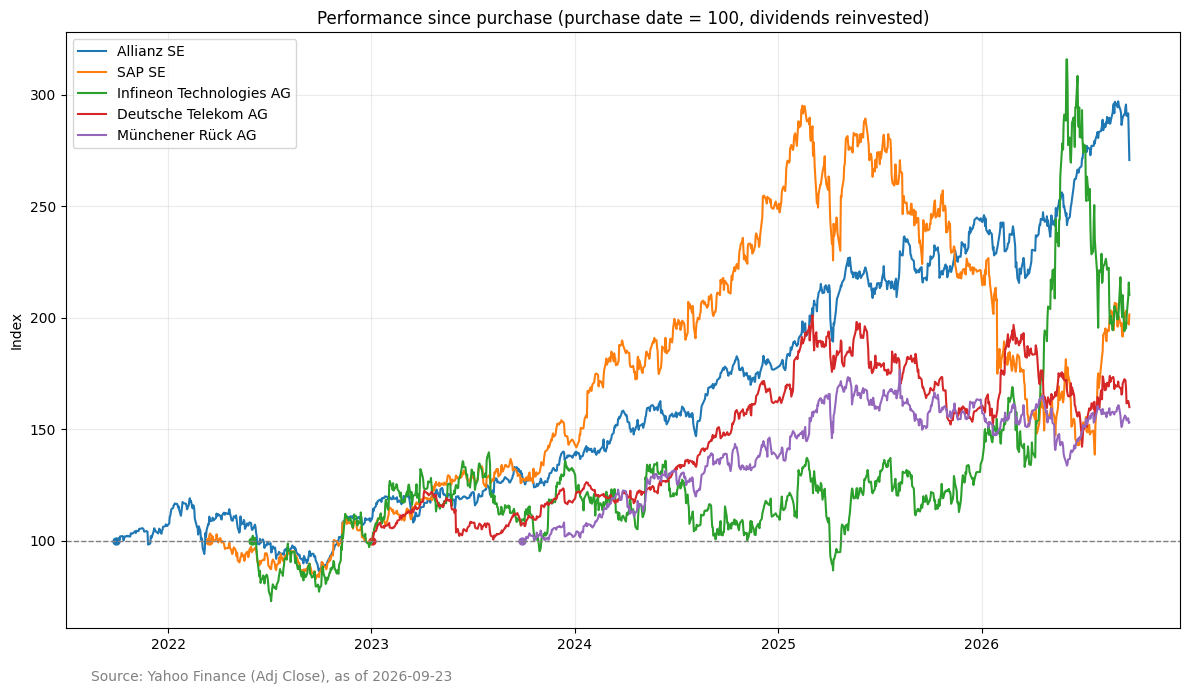

In [20]:
fig, ax = plt.subplots(figsize=(12, 7))
returns = {}

for stock in portfolio:
    series = adj_close.loc[stock["buy_date"]:end_date, stock["ticker"]].dropna()
    index = series / series.iloc[0] * 100
    line, = ax.plot(index.index, index, label=stock["name"])
    ax.scatter(index.index[0], 100, color=line.get_color(), s=25)
    returns[stock["name"]] = series.iloc[-1] / series.iloc[0] - 1

ax.axhline(100, color="gray", linestyle="--", linewidth=1)
ax.set_title("Performance since purchase (purchase date = 100, dividends reinvested)")
ax.set_ylabel("Index")
ax.legend(loc="upper left")
ax.grid(alpha=0.25)
fig.text(0.08, 0.02, f"Source: Yahoo Finance (Adj Close), as of {end_date}", color="gray")
fig.tight_layout(rect=(0, 0.04, 1, 1))
plt.show()

returns = pd.Series(returns).sort_values(ascending=False)

In [21]:
returns = pd.Series(returns).sort_values(ascending=False)
print(f"Am besten entwickelt hat sich {returns.index[0]} mit {returns.iloc[0]:.2%} seit dem Kauf.")

Am besten entwickelt hat sich Allianz SE mit 170.63% seit dem Kauf.


### Aufgabe 1:
Baut die Grafik in Python nach. Sie soll inhaltlich identisch sein: gleiche Daten, gleicher Diagrammtyp, gleicher Titel, gleiche Achsenbeschriftung und Legende. Farben und Größen müssen nur sinngemäß übereinstimmen.

### Lösung
Am besten entwickelt hat sich Allianz SE mit 170.63% seit dem Kauf.

### Aufgabe 2:
Beantwortet die beiden Fragen von Frau Keller:
   - „Welche meiner Aktien hat sich seit dem Kauf am besten entwickelt?“
   - „Warum kann ich das nicht einfach an den Aktienkursen in Euro ablesen?“

### Lösung
Aktienkurse in Euro sind nicht direkt vergleichbar, weil die Kaufkurse unterschiedlich sind.
Der Index setzt jede Aktie am jeweiligen Kaufdatum auf 100 und zeigt die prozentuale Entwicklung.
Die bereinigten Kurse berücksichtigen die Wiederanlage der Dividenden.